# Estabilidade

Um sistema é assintoticamente estável quando, depois de perturbado, retorna ao ponto de operação em vez de se afastar dele. Este notebook testa a estabilidade de duas formas: pelos **autovalores** de $\mathbf{A}$ e pelo **mapa de fase**, que mostra as trajetórias dos estados a partir de diferentes condições iniciais.

## Autovalores

Sem perturbação nas entradas, os estados evoluem como combinações de termos $e^{\lambda_i t}$, em que $\lambda_i$ são os autovalores de $\mathbf{A}$, isto é, as raízes da equação característica:

$$\det(\lambda\mathbf{I} - \mathbf{A}) = 0$$

Cada termo decai se $\mathrm{Re}(\lambda_i) < 0$ e cresce se $\mathrm{Re}(\lambda_i) > 0$, e a parte imaginária só causa oscilações. Assim, o ponto estacionário é estável se todos os autovalores têm parte real negativa e instável se algum tem parte real positiva.

Aqui, os autovalores são calculados numericamente com a biblioteca NumPy.


In [7]:
import hickle as hkl
import numpy as np

A = np.array(hkl.load("../outputs/A.hkl"), dtype=float)
B = np.array(hkl.load("../outputs/B.hkl"), dtype=float)
C = np.array(hkl.load("../outputs/C.hkl"), dtype=float)

lams = np.linalg.eigvals(A)
print(
    f"λ = {lams.real.round(1)} | {'ESTÁVEL' if (lams.real < 0).all() else 'INSTÁVEL'}"
)


λ = [-52.9 -52.9 -48.  -48.   -3.2  -7.   -7.  -49.6 -33.8] | ESTÁVEL


## Mapa de fase

Para visualizar a estabilidade, simula-se a resposta livre do modelo linear, com as entradas nos valores nominais, a partir de 12 condições iniciais aleatórias próximas do ponto estacionário. Como o sistema tem 9 estados, o mapa de fase é dividido em três gráficos 3D: temperaturas, fração molar de A e fração molar de B. Em cada um, os três eixos correspondem ao reator 1, ao reator 2 e ao separador. Cada gráfico é uma projeção do espaço de fase de 9 dimensões, então trajetórias diferentes podem parecer se cruzar. Se o sistema é estável, todas as trajetórias (pontos pretos são as condições iniciais) convergem para o ponto estacionário (ponto vermelho).


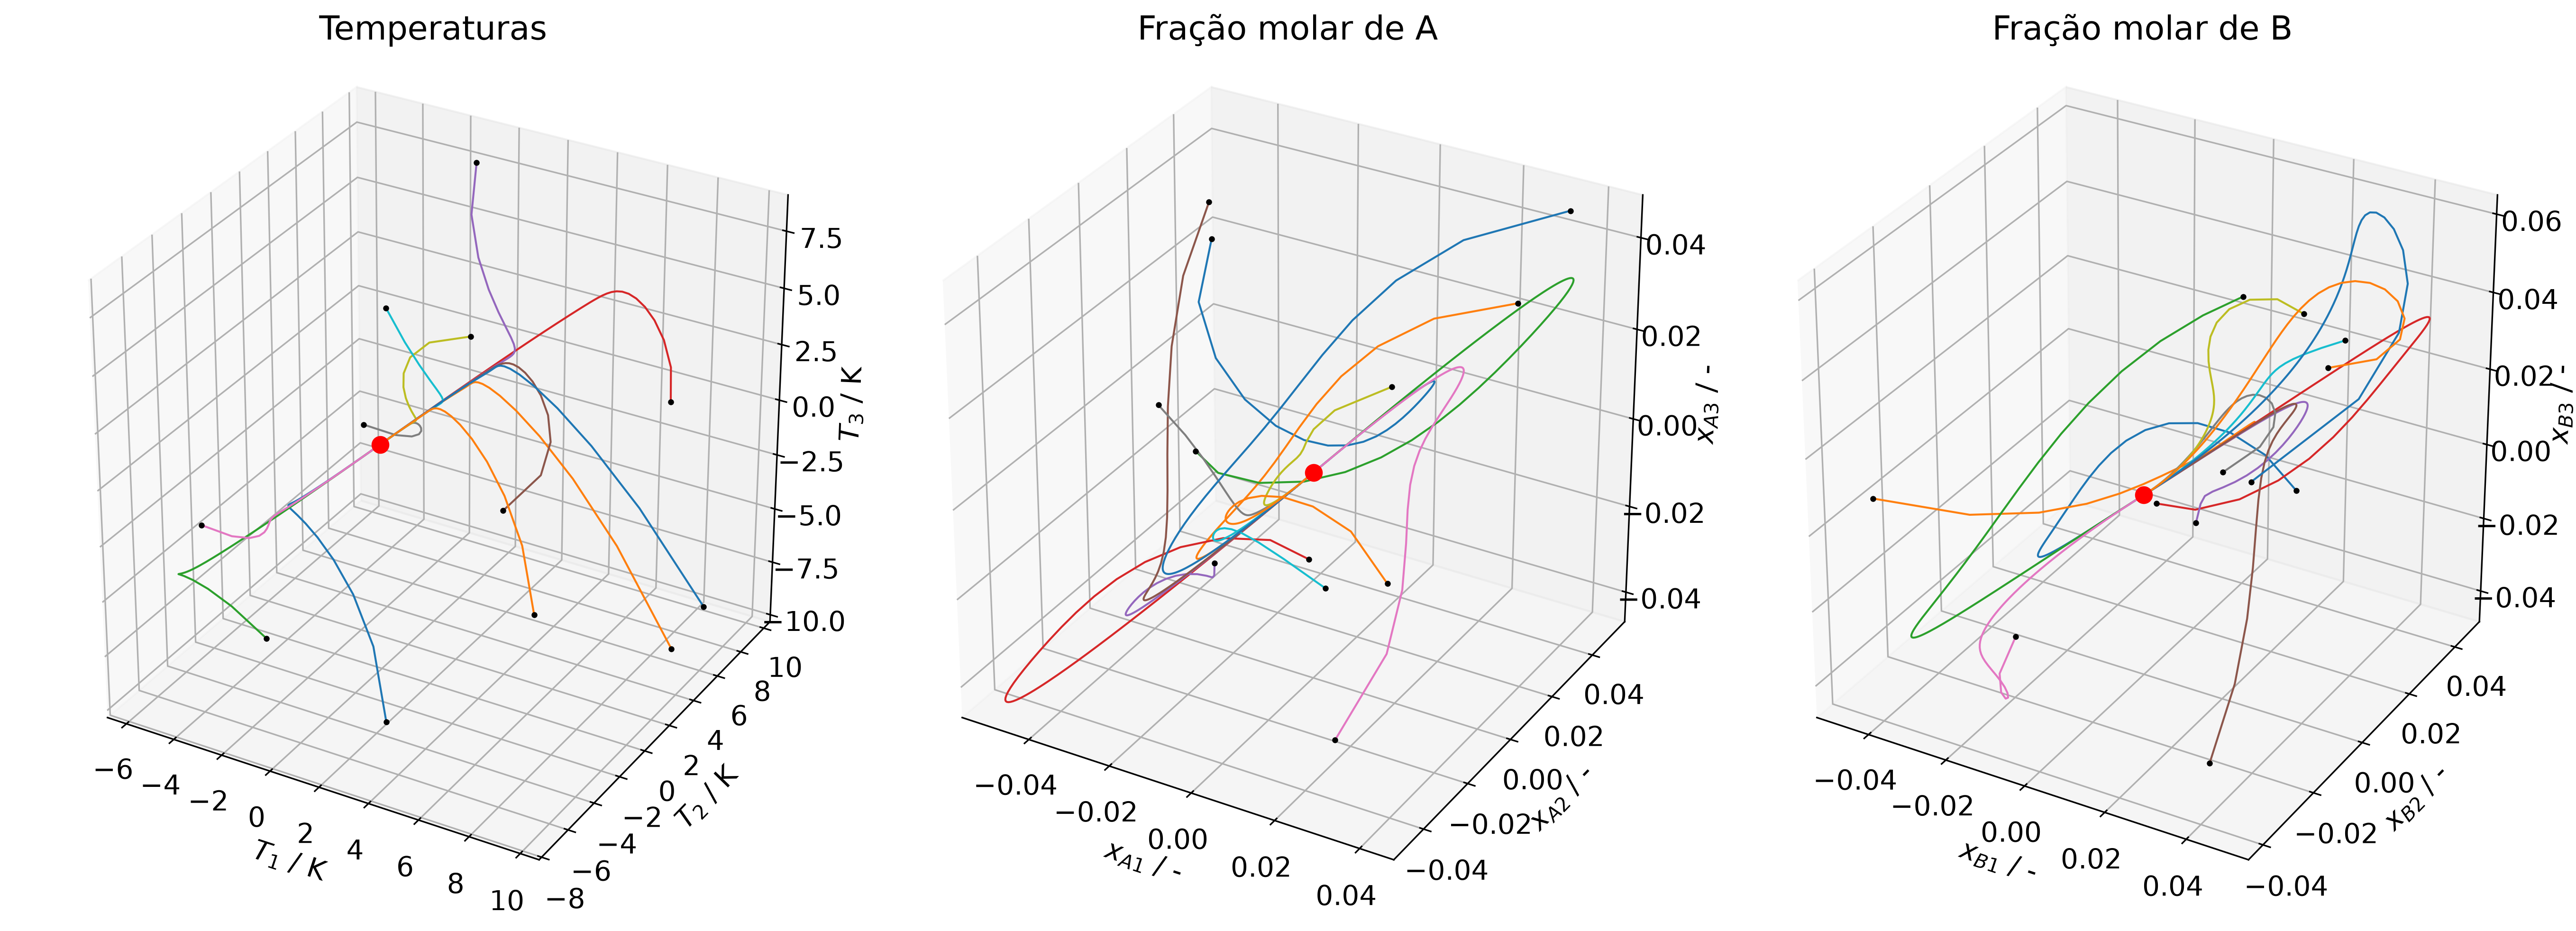

In [8]:
import control as ctrl

from lib.plots import plot_and_show, plt
from lib.utils import output_labels, output_units

# Estados que entram em cada gráfico: x = [T1 T2 T3 xA1 xB1 xA2 xB2 xA3 xB3]
grupos = {
    "Temperaturas": [0, 1, 2],
    "Fração molar de A": [3, 5, 7],
    "Fração molar de B": [4, 6, 8],
}

# Desvios iniciais: ± 10 K nas temperaturas e ± 0,05 nas frações molares
rng = np.random.default_rng(0)
delta = np.r_[np.full(3, 10.0), np.full(6, 0.05)]
dX0 = rng.uniform(-1, 1, size=(12, 9)) * delta

tt = np.linspace(0, 2, 200)
sys = ctrl.StateSpace(A, B, C, np.zeros_like(B))

# Resposta livre em variáveis de desvio
trajs = [ctrl.initial_response(sys, tt, X0=dx0, return_x=True).states.T for dx0 in dX0]  # type: ignore

fig = plt.figure(figsize=(18, 8), constrained_layout=True)
for k, (titulo, idx) in enumerate(grupos.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")

    for traj in trajs:
        ax.plot(*traj[:, idx].T, lw=1)
    ax.plot(*dX0[:, idx].T, "k.", ms=4)
    ax.plot(0, 0, 0, "ro", ms=8)

    rotulos = [f"{output_labels[i]} / {output_units[i]}" for i in idx]
    ax.set(xlabel=rotulos[0], ylabel=rotulos[1], zlabel=rotulos[2], title=titulo)
    ax.set_box_aspect((1, 1, 1))

plot_and_show("mapa_de_fase")
